En este ejercicio se construyó un ensamble CWOE de 50 matrices con parámetros \(N=300\), \(T=50\) y \(c=0.2\), utilizando el código desarrollado en el ejercicio 4. Se calcularon los autovalores de cada matriz y se construyó un histograma para analizar su distribución espectral. Posteriormente, se aplicó el mapa de potencia para los valores \(q=1,1.01,1.5,2,5\). Para cada valor de \(q\), se calcularon nuevamente los autovalores y se generaron sus respectivos histogramas. Finalmente, se compararon las distribuciones obtenidas para estudiar cómo influye el parámetro \(q\) en el espectro de las matrices.

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import sqrtm

Creamos la matriz con la que vamos a trabajar, para ello vamos a utilizar los códigos que programamos en el ejercicio 4. 

In [12]:
def matriz_D(N, T): # Función utilizada en en el ejercicio 4 
    D = np.random.normal(0, 1, size=(N, T))
    return D

In [13]:
def Xi(N, c):
    Xi = np.full((N,N),c, dtype= float) 
    """Este parte de aquí nos ayuda a crear la matriz de NxN, con el full llenamos los valores de c,
    y nada más rellenamos con unos en la diagonal"""
    np.fill_diagonal(Xi, 1)
    """Esta parte de aquí nos ayuda a rellenar con unos la diagonal"""
    return Xi

In [14]:
def X(N,T,c):
    D = matriz_D(N, T)
    Xi_mat = Xi(N, c)
    Xi_sqrt = sqrtm(Xi_mat)
    X = Xi_sqrt @ D
    return X
    # Creamos nuestra función que haga el calculo de X, para ello necesitamos una libreria scipy.linalg 

def C(N,T,c):
    X_math = X(N,T,c)
    C = (X_math @ X_math.T) / T
    return C
    # Creamos nuestra última matriz que hará comparar los datos

Ya generamos la la función para una matriz, ahora vamos a generar las 50 matrices y vamos a calcular los valores propios de cada una de las matrices, esperamos tener 300 valores propios de 50 matrices, tendremos un arreglo de 15000 valores propios

In [15]:
N = 300
T = 50
valor = 0.2
autovalores_C = []
matrices_C = []
for i in range(50):
     
    C_math = C(N,T,valor) # Generamos las matrices con nuestro código anterior. 
    matrices_C.append(C_math) # Guardamos cada matriz, las necesitamos más adelante 
    autovalores = np.linalg.eigvalsh(C_math) # Calculamos los eigenvalores reales. 
    autovalores_C.extend(autovalores) #Guardamos los valores propios

matrices_C = np.array(matrices_C)
autovalores_C = np.array(autovalores_C)

In [16]:
print(autovalores_C.shape)
print(matrices_C.shape)

(15000,)
(50, 300, 300)


Ahora vamos a construir el histograma
El pico cercano a cero: aparece porque \(N=300>T=50\), por lo que cada matriz tiene al menos 250 autovalores nulos.

Los autovalores grandes: están asociados con las correlaciones introducidas mediante \(c=0.2\), que producen un modo colectivo.

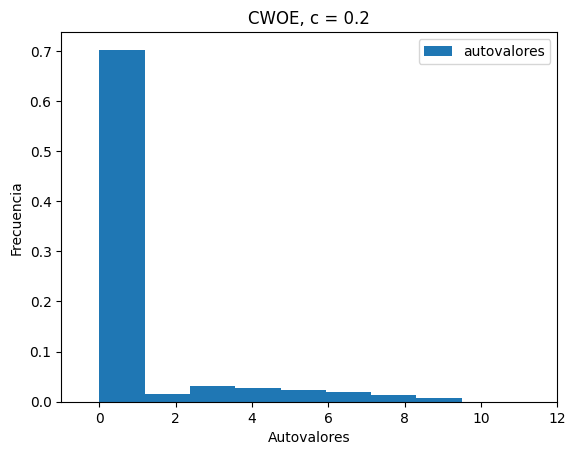

In [17]:
plt.hist(autovalores_C, density= True, label = "autovalores", bins = 80)
plt.xlabel("Autovalores")
plt.ylabel("Frecuencia")
plt.title("CWOE, c = 0.2")
plt.xlim(-1, 12)
plt.legend()
plt.show()

Vamos aplicar el mapa de potencia para los diferentes valores de \(q\).

In [18]:
q_list = [1, 1.01, 1.5, 2, 5 ]

In [19]:
q_list = [1, 1.01, 1.5, 2, 5]
matrices_C_q = []

for q in q_list:
    C_q = np.sign(matrices_C) * (np.abs(matrices_C) ** q)
    matrices_C_q.append(C_q)
matrices_C_q = np.array(matrices_C_q)

In [20]:
matrices_C_q.shape

(5, 50, 300, 300)

Ahora vamos a calcular los autovalores de cada matriz transformada

In [21]:
autovalores_tranformados = [[], [], [], [], []]
for i in range(5):
    for j in range(50):
        autovalor_C_q = np.linalg.eigvalsh(matrices_C_q[i, j])
        autovalores_tranformados[i].append(autovalor_C_q)
autovalores_tranformados = np.array(autovalores_tranformados)

In [22]:
autovalores_tranformados.shape

(5, 50, 300)

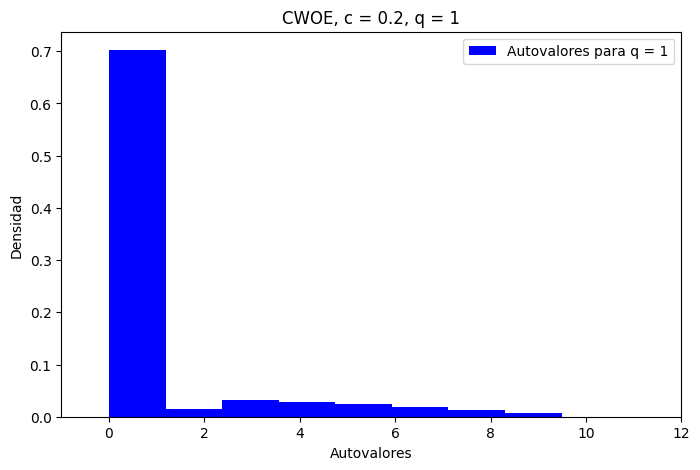

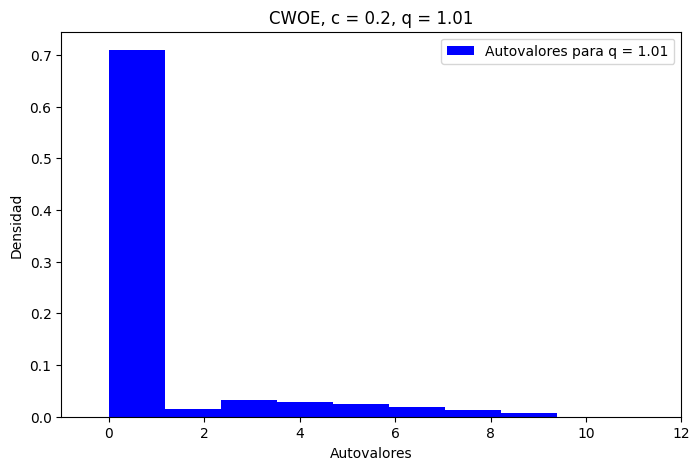

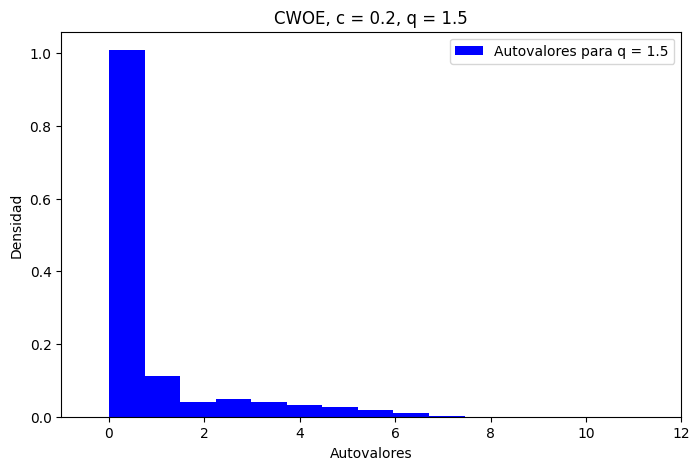

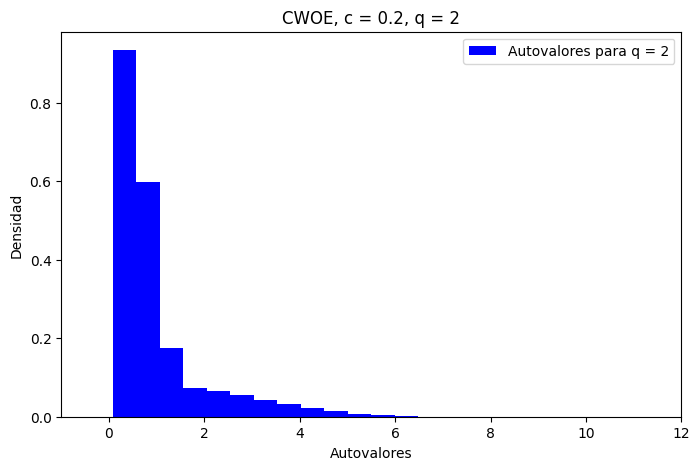

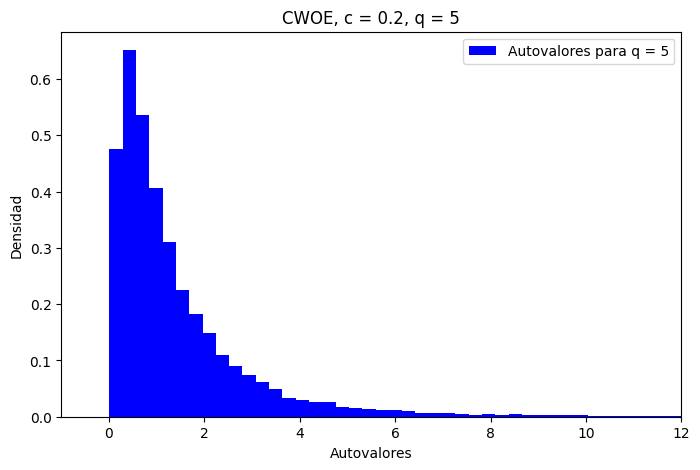

In [28]:
for i in range(5):
    plt.figure(figsize=(8, 5))
    plt.hist(autovalores_tranformados[i].ravel(), density=True,
              label=f"Autovalores para q = {q_list[i]}", bins=80, color = "blue")
    plt.xlabel("Autovalores")
    plt.ylabel("Densidad")
    plt.title(f"CWOE, c = 0.2, q = {q_list[i]}")
    plt.xlim(-1, 12)
    plt.legend()
    plt.show()

Al comparar los histogramas de autovalores del ensamble CWOE, se observa que la distribución espectral cambia conforme aumenta el parámetro (q).

Para (q=1), el mapa de potencia no modifica la matriz original. El histograma presenta una fuerte concentración de autovalores cercanos a cero, debido a que (N=300>T=50), por lo que la matriz de correlación tiene al menos 250 autovalores nulos. Para (q=1.01), la distribución prácticamente no cambia, ya que la transformación introduce una perturbación muy pequeña.

Cuando (q=1.5) y (q=2), la concentración de autovalores cerca de cero comienza a disminuir y la distribución se extiende hacia valores positivos. Esto ocurre porque el mapa de potencia reduce la magnitud de las correlaciones fuera de la diagonal, modificando la estructura espectral de las matrices. Además, la transformación puede eliminar la degeneración de los autovalores nulos de la matriz original.

Finalmente, para (q=5), la distribución presenta una forma más continua y una mayor dispersión de autovalores positivos. Esto se debe a que las correlaciones fuera de la diagonal se vuelven mucho más pequeñas, mientras que los elementos diagonales permanecen cercanos a la unidad.